# One generator, one scheduling week

Explore **Tokke_G2** for the case starting **2021-01-01**: its 168 hourly
ON/OFF labels alongside that week's electricity prices, starting reservoir
volumes and terminal water values. Change the settings
below to inspect another labelled case.

The labels are **decisions from an optimisation solver** for this particular
weekly case. They depend on the full scheduling problem, including water
availability and constraints. This notebook reads the original CSVs without
changing them and does not train a model.

**Run in VS Code:** select the project's `.venv` Python interpreter as the
notebook kernel, then click **Run All**. Dependencies are listed in
`requirements-eda.txt`. To recreate the environment, run these commands from
the repository root:

```bash
python3.12 -m venv .venv
.venv/bin/python -m pip install -r requirements-eda.txt
```

In [1]:
from pathlib import Path
from datetime import timezone
import re
import yaml

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

GENERATOR = "Tokke_G2"
CASE_START = "2021-01-01"  # A case start date in the labelled 2015–2022 data.
HORIZON_HOURS = 168

## Find the data and select one case

The notebook works when launched from the repository root or `notebooks/`.
Each `_tN` column is an hour relative to the case start. Select only this
generator's columns and sort them by the **numeric** hour index, so `t10`
cannot accidentally appear before `t2`. `Run No` identifies the case; it is
not a prediction input. `total_calculation_time` is not used.

In [2]:
root_candidates = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next(
    (p for p in root_candidates
     if (p / "data/raw/kernel/Unit_commitment_decisions.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from the project root or notebooks/.")

DATA_DIR = PROJECT_ROOT / "data/raw/kernel"
LABEL_PATH = DATA_DIR / "Unit_commitment_decisions.csv"
PRICE_PATH = DATA_DIR / "Historical_day_ahead_price_2015_2025.csv"

header = pd.read_csv(LABEL_PATH, nrows=0).columns
pattern = re.compile(rf"^result_committed_{re.escape(GENERATOR)}_t(\d+)$")
matched = [(int(match.group(1)), col) for col in header
           if (match := pattern.fullmatch(col))]
matched.sort(key=lambda item: item[0])
if [hour for hour, _ in matched] != list(range(HORIZON_HOURS)):
    raise ValueError(f"Expected exactly t0–t167 for {GENERATOR}; check its name.")
label_columns = [col for _, col in matched]

cases = pd.read_csv(LABEL_PATH, usecols=["Run No", "starttime", *label_columns])
cases["starttime"] = pd.to_datetime(cases["starttime"], utc=True)
start = pd.Timestamp(CASE_START, tz="UTC")
selected = cases.loc[cases["starttime"].eq(start)]
if len(selected) != 1:
    raise ValueError(f"Expected one labelled case for {CASE_START}, found {len(selected)}.")

case = selected.iloc[0]
raw_schedule = case[label_columns]
if raw_schedule.isna().any() or not raw_schedule.isin([0, 1]).all():
    raise ValueError("Selected schedule must contain 168 non-missing binary labels.")
schedule = raw_schedule.to_numpy(dtype=np.int8)
hours = pd.date_range(start=start, periods=HORIZON_HOURS, freq="h")
end = start + pd.Timedelta(hours=HORIZON_HOURS)
run_no = int(case["Run No"])
print(f"Case {run_no} | {GENERATOR} | {start} to {end} (end excluded)")

Case 2193 | Tokke_G2 | 2021-01-01 00:00:00+00:00 to 2021-01-08 00:00:00+00:00 (end excluded)


## Align prices by UTC timestamp

The forecast window includes its first hour and excludes the timestamp at
`start + 168 hours`. Both files use UTC. Match prices by timestamp rather
than by row position, and check for missing or duplicate hours.

In [3]:
PRICE_COLUMN = "Day-ahead price (EUR/MWh)"
prices = pd.read_csv(PRICE_PATH, usecols=["date", PRICE_COLUMN])
prices["date"] = pd.to_datetime(prices["date"], utc=True)
window = prices.loc[prices["date"].ge(start) & prices["date"].lt(end)].copy()
if window["date"].duplicated().any():
    raise ValueError("Duplicate price timestamps in the selected week.")
if len(window) != HORIZON_HOURS:
    raise ValueError(f"Expected 168 hourly prices, found {len(window)}.")
aligned_prices = window.set_index("date")[PRICE_COLUMN].reindex(hours)
if aligned_prices.isna().any() or not np.isfinite(aligned_prices.to_numpy()).all():
    raise ValueError("Missing or non-finite prices after hourly alignment.")

week = pd.DataFrame({
    "hour_in_case": np.arange(HORIZON_HOURS),
    "on": schedule,
    "price_eur_per_mwh": aligned_prices.to_numpy(),
}, index=hours)
week.index.name = "timestamp_utc"
assert len(week) == 168 and week.index.is_unique
display(week.head(8))

,hour_in_case,on,price_eur_per_mwh
timestamp_utc,,,
2021-01-01 00:00:00+00:00,0,0,24.35
2021-01-01 01:00:00+00:00,1,0,23.98
2021-01-01 02:00:00+00:00,2,0,23.72
2021-01-01 03:00:00+00:00,3,0,23.73
2021-01-01 04:00:00+00:00,4,0,24.06
2021-01-01 05:00:00+00:00,5,0,24.44
2021-01-01 06:00:00+00:00,6,0,24.93
2021-01-01 07:00:00+00:00,7,0,24.90


In [4]:
on_hours = int(week["on"].sum())
# Count changes between adjacent hours inside this week only.
switches = int(week["on"].diff().dropna().ne(0).sum())
summary = pd.Series({
    "Case ID": run_no,
    "Generator": GENERATOR,
    "First hour (UTC)": hours[0],
    "Last hour (UTC)": hours[-1],
    "ON hours": on_hours,
    "OFF hours": HORIZON_HOURS - on_hours,
    "ON share": f"{on_hours / HORIZON_HOURS:.1%}",
    "ON/OFF switches within week": switches,
    "Minimum price (EUR/MWh)": round(week["price_eur_per_mwh"].min(), 2),
    "Maximum price (EUR/MWh)": round(week["price_eur_per_mwh"].max(), 2),
}, name="Value")
display(summary.to_frame())

,Value
Case ID,2193
Generator,Tokke_G2
First hour (UTC),2021-01-01 00:00:00+00:00
Last hour (UTC),2021-01-07 23:00:00+00:00
ON hours,71
OFF hours,97
ON share,42.3%
ON/OFF switches within week,5
Minimum price (EUR/MWh),23.49
Maximum price (EUR/MWh),99.91


## Add the reservoir context

Read the supplied topology to find the plant containing the selected generator
and the reservoirs feeding it, including tunnel connections. For the default
example the path is **Vinjevatn → Tokke → Bandak**. Vinjevatn also receives
water from upstream plants, so its local inflow alone would not describe all
water arriving there.

For each feeding reservoir, inspect two case boundary inputs specified by the
dataset documentation:

- **Starting volume:** storage at the start of this case, January 1, 2021 for
  the default example. We do not use later daily volumes as this case's inputs.
- **Terminal water value:** the value at `start + 168 hours`, January 8, 2021
  for the default example. It represents the marginal value assigned to water
  remaining at the end of the scheduling week.

The table also compares starting volume with the topology's configured
`max_vol`. These are reservoir-level inputs shared by generators using that
reservoir; this table does not allocate water to individual generators.

In [5]:
with (PROJECT_ROOT / "configs/Tokke_Vinje_topology.yaml").open() as handle:
    topology = yaml.safe_load(handle)
connections = topology["connections"]
plants = [c["to"] for c in connections
          if c["from"] == GENERATOR and c["from_type"] == "generator"
          and c["to_type"] == "plant"]
if len(plants) != 1:
    raise ValueError(f"Expected one plant for {GENERATOR}, found {plants}.")
plant = plants[0]

# Follow incoming reservoir/tunnel links; stop at the first reservoirs.
# Some plants (e.g. Songa) have more than one feeding reservoir.
upstream = []
pending = [(plant, "plant")]
visited = set()
while pending:
    target = pending.pop()
    if target in visited:
        continue
    visited.add(target)
    for link in connections:
        if (link["to"], link["to_type"]) != target:
            continue
        if link["from_type"] == "reservoir":
            upstream.append(link["from"])
        elif link["from_type"] == "tunnel":
            pending.append((link["from"], "tunnel"))
reservoirs = sorted(set(upstream))
if not reservoirs:
    raise ValueError(f"No feeding reservoirs found for {plant}.")
outlets = sorted({c["to"] for c in connections
                  if c["from"] == plant and c["from_type"] == "plant"
                  and c["to_type"] == "reservoir"})
print(f"Topology: {', '.join(reservoirs)} → {plant} → {', '.join(outlets)}")


def boundary_values(filename, timestamp):
    data = pd.read_csv(DATA_DIR / filename, usecols=["date", *reservoirs])
    data["date"] = pd.to_datetime(data["date"], utc=True)
    selected_boundary = data.loc[data["date"].eq(timestamp), reservoirs]
    if len(selected_boundary) != 1:
        raise ValueError(f"Expected one row in {filename} at {timestamp}.")
    values = selected_boundary.iloc[0].astype(float)
    if not np.isfinite(values.to_numpy()).all():
        raise ValueError(f"Missing or non-finite boundary values in {filename}.")
    return values


initial_volume = boundary_values("Historical_volume_2015_2024.csv", start)
terminal_water_value = boundary_values("Synthetic_water_value_2015_2024.csv", end)
maximum_volume = pd.Series({
    name: float(topology["model"]["reservoir"][name]["max_vol"])
    for name in reservoirs
})
if (initial_volume < 0).any() or (maximum_volume <= 0).any():
    raise ValueError("Expected non-negative storage and positive configured maximum volumes.")
reservoir_context = pd.DataFrame({
    "Starting volume (million m³)": initial_volume,
    "Configured maximum (million m³)": maximum_volume,
    "Starting fill (%)": 100 * initial_volume / maximum_volume,
    "Terminal water value (EUR/MWh)": terminal_water_value,
})
reservoir_context.index.name = "Feeding reservoir"
print(f"Starting volumes: {start}; terminal water values: {end}")
display(reservoir_context.round(3))

Topology: Vinjevatn → Tokke → Bandak
Starting volumes: 2021-01-01 00:00:00+00:00; terminal water values: 2021-01-08 00:00:00+00:00


,Starting volume (million m³),Configured maximum (million m³),Starting fill (%),Terminal water value (EUR/MWh)
Feeding reservoir,,,,
Vinjevatn,6.283,9.36,67.126,42.82


## View the weekly schedule with water value

The upper panel shows the solver's binary labels; the lower panel shows
hourly electricity prices and the feeding reservoir's terminal water value.
Each state lasts for one hour. The starting volumes are in the table above.

The dashed water-value reference is flat because it is **one end-of-week
input**, not an hourly series. Its height gives context for the value of
saving water, but it is **not an exact ON/OFF price threshold**. Cascaded
plants, downstream water values, efficiencies, inflows and constraints also
matter. These plots do not establish what caused a particular decision.

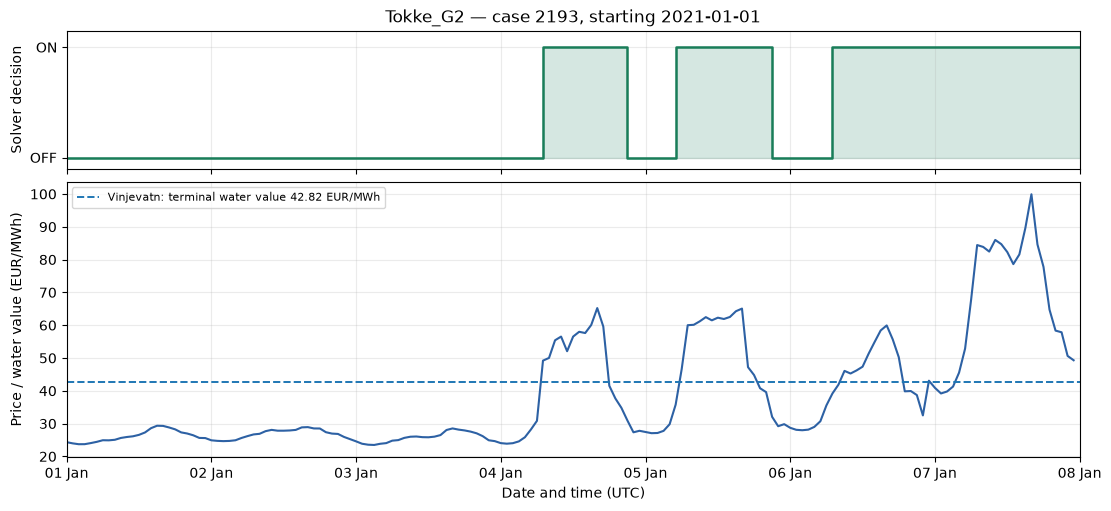

In [6]:
fig, (ax_schedule, ax_price) = plt.subplots(
    2, 1, figsize=(11, 5), sharex=True,
    gridspec_kw={"height_ratios": [1, 2]}, constrained_layout=True,
)
# Extend the last state to the end of its hour, without adding a new label.
edges = hours.append(pd.DatetimeIndex([end]))
states = np.r_[schedule, schedule[-1]]
ax_schedule.step(edges, states, where="post", color="#197d59", linewidth=1.8)
ax_schedule.fill_between(edges, states, 0, step="post", color="#197d59", alpha=0.18)
ax_schedule.set_yticks([0, 1], labels=["OFF", "ON"])
ax_schedule.set_ylim(-0.1, 1.15)
ax_schedule.set_ylabel("Solver decision")
ax_schedule.set_title(f"{GENERATOR} — case {run_no}, starting {start:%Y-%m-%d}")

ax_price.plot(hours, week["price_eur_per_mwh"], color="#2d61a4", linewidth=1.5)
for reservoir in reservoirs:
    value = terminal_water_value[reservoir]
    ax_price.axhline(
        value, linestyle="--", linewidth=1.4,
        label=f"{reservoir}: terminal water value {value:.2f} EUR/MWh",
    )
ax_price.legend(loc="upper left", fontsize=8)
ax_price.set_ylabel("Price / water value (EUR/MWh)")
ax_price.set_xlabel("Date and time (UTC)")
ax_price.xaxis.set_major_locator(mdates.DayLocator(tz=timezone.utc))
ax_price.xaxis.set_major_formatter(mdates.DateFormatter("%d %b", tz=timezone.utc))
ax_price.set_xlim(start, end)
for ax in (ax_schedule, ax_price):
    ax.grid(True, alpha=0.25)
plt.show()

## What to take from this example

- Compare the ON/OFF periods with the price curve and the terminal water-value
  reference. This is one illustrative case, not evidence of a general rule.
- The starting volume describes the reservoir's initial condition for the whole
  case. It does not show the storage trajectory produced by this weekly plan.
- For the default case, Vinjevatn starts with **6.283 million m³**, about **67.1%**
  of its configured maximum, and has a terminal water value of **42.82 EUR/MWh**.
  The table and plot update when the case or generator changes.
- The solver also considers other reservoirs and generators. A simple comparison
  of electricity price with this single reservoir's water value will not explain
  the complete schedule.
- Next, examine reservoir inflows and upstream water transfers. Direct reservoir
  inflow is only one component of water arriving in a cascaded system.
- Changing the start date creates a different weekly planning problem; overlapping
  calendar hours can have different labels. No model is trained here.